# 04 — Attribution: is the diffusion compression policy-targeted?

Reproduces the attribution analysis of *"Deepening before dissolution: non-monotonic
escape dynamics in the scaling exponents of county economies"* (§2.6 and SI Text S5):
the coarse quasi-difference-in-differences test on the $B$-ratio reversal, the
state-conditioned fixed-effects regression that separates a designation margin from a
state margin, the pre-period placebo and crisis-exclusion robustness checks, the
endogenous break search that lets the break year float over 2005–2017, and the
year-by-year event-time coefficients. Together these establish that the poverty-basin
diffusion compression is state-targeted and synchronised with the 2013 campaign onset,
while showing why attribution to the poverty campaign *specifically* is not identified.

In [1]:
import os, sys
sys.path.insert(0, '/home/yushentang/EconP-release')
os.chdir('/home/yushentang/EconP-release')
sys.path.insert(0, 'scripts')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_merger import load_panel
from src.saai import compute_saai
from src.robustness import bratio_did_test
from src.config import FP_PERIODS

# the attribution designs live in scripts/, and are imported rather than reimplemented
from run_attribution_designs import build_increments, within_ols

COL = {"pre": "#4575b4", "during": "#e6a817", "post": "#d73027"}
print("FP periods:", FP_PERIODS)

/home/yushentang/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


FP periods: {'pre': (2000, 2012), 'during': (2013, 2019), 'post': (2020, 2023)}


## 1. The coarse quasi-difference-in-differences design

The $B$-ratio $B(\xi<0)/B(\xi\geq 0)$ flips from 1.55 to 0.56 between the pre and
campaign periods (§2.6). The first attribution question is whether that flip is
specific to the counties the campaign designated. Splitting the transition pairs by
designation status and re-running the binned Kramers–Moyal estimator within each cell
gives a two-by-two contrast,

$$\Delta\Delta B = \bigl(B^{\mathrm{pov}}_{\mathrm{during}}-B^{\mathrm{pov}}_{\mathrm{pre}}\bigr)
-\bigl(B^{\mathrm{nonpov}}_{\mathrm{during}}-B^{\mathrm{nonpov}}_{\mathrm{pre}}\bigr),$$

which is negative if designated counties compressed more. The point estimate is
computed live below on the multi-factor SAAI panel.

In [2]:
panel = load_panel("panel_scaling")
saai_multi = compute_saai(panel, y_col="GrossOutputValue",
                          x_cols=["PopNum", "CultivateArea"])
labels = panel[["Year", "CountyCode", "IsPoverty"]].drop_duplicates(["Year", "CountyCode"])
saai_lab = saai_multi.merge(labels, on=["Year", "CountyCode"], how="left")

did = bratio_did_test(saai_lab)

paper_cells = {("poverty", "pre"): 1.16, ("poverty", "during"): 0.65,
               ("nonpoverty", "pre"): 1.54, ("nonpoverty", "during"): 0.49}
print("B-ratio B(xi<0)/B(xi>=0) by designation status and period:")
for grp in ("poverty", "nonpoverty"):
    for per in ("pre", "during"):
        d = did[grp][per]
        print(f"  {grp:>10} {per:>6}: B-ratio = {d['B_ratio']:.3f} "
              f"({d['n_pairs']:,} pairs)   (paper reports: {paper_cells[(grp, per)]:.2f})")

print(f"\nddB = {did['did_estimate']:+.3f}   (paper reports: +0.53)")
print(f"  {did['interpretation']}")

Loaded: /home/yushentang/EconP-release/data_clean/panel_scaling.parquet (19,392 rows, 64 cols)
B-ratio B(xi<0)/B(xi>=0) by designation status and period:
     poverty    pre: B-ratio = 1.163 (1,935 pairs)   (paper reports: 1.16)
     poverty during: B-ratio = 0.655 (825 pairs)   (paper reports: 0.65)
  nonpoverty    pre: B-ratio = 1.536 (3,925 pairs)   (paper reports: 1.54)
  nonpoverty during: B-ratio = 0.494 (909 pairs)   (paper reports: 0.49)

ddB = +0.534   (paper reports: +0.53)
  DiD >= 0 implies B-ratio change is similar across groups (secular trends may explain the reversal)


The uncertainty on $\Delta\Delta B$ comes from a county-block bootstrap
($B = 2{,}000$ stratified county resamples, seed 101), generated by
`scripts/run_escape_dynamics.py --steps g2`. That is a heavy computation and is
**not rerun here**; the summary is read from `results/tables/quasi_did_bootstrap.csv`.

In [3]:
# Full regeneration (heavy): python3 scripts/run_escape_dynamics.py --steps g2
g2 = pd.read_csv("results/tables/quasi_did_bootstrap.csv")
row = g2[(g2.spec == "multi") & (g2.panel == "panel_scaling") & (g2.variant == "main")].iloc[0]
print(f"ddB = {row['point']:+.2f}  SE = {row['se']:.2f}  "
      f"95% CI [{row['ci_lo']:+.2f}, {row['ci_hi']:+.2f}]  "
      f"({int(row['n_used']):,} usable draws)")
print("paper reports: ddB = +0.53, SE = 0.73, 95% CI [-1.04, +2.05], B = 2,000")

alt = g2[(g2.spec == "multi") & (g2.variant == "during_incl_2020")].iloc[0]
print(f"\ncampaign window extended to 2020: ddB = {alt['point']:+.2f} "
      f"[{alt['ci_lo']:+.2f}, {alt['ci_hi']:+.2f}]   (paper reports: +0.53 [-0.98, +2.05])")

ddB = +0.53  SE = 0.73  95% CI [-1.04, +2.05]  (1,999 usable draws)
paper reports: ddB = +0.53, SE = 0.73, 95% CI [-1.04, +2.05], B = 2,000

campaign window extended to 2020: ddB = +0.53 [-0.98, +2.05]   (paper reports: +0.53 [-0.98, +2.05])


The interval covers zero comfortably, and the sign is the *opposite* of the policy
hypothesis. The reason is visible in the four cells: **both** groups compress strongly
(poverty $1.16 \to 0.65$, non-poverty $1.54 \to 0.49$), so the coarse two-by-two design
detects no differential effect of designation. Extending the campaign window to include
2020 leaves the estimate unchanged, so the null is not an artefact of the window's COVID
boundary.

This is not evidence that the compression is unrelated to policy. The design confounds
designation with **state**: diffusion is U-shaped in $\xi$, and designated counties sit
disproportionately in the poverty basin, so a comparison that ignores $\xi$ mixes the two.

## 2. State-conditioned regression: separating designation from state

The finer design regresses the log squared one-year SAAI increment on a flexible
function of the current state plus interaction terms,

$$\log(\Delta\xi)^{2}_{it} = f(\xi_{it})
+ \beta_{1}\,(\mathrm{designated}_i \times \mathrm{during}_t)
+ \beta_{2}\,(\mathbb{1}[\xi_{it}<0] \times \mathrm{during}_t)
+ \mu_i + \lambda_t + \varepsilon_{it},$$

with cubic $f$, county and year fixed effects, and county-clustered standard errors,
over 2000–2019. Specification S1 includes the designation margin only; S2 adds the state
margin $\mathbb{1}[\xi<0]\times$ during. Both are fit live using `build_increments` and
`within_ols` from `scripts/run_attribution_designs.py`.

In [4]:
inc = build_increments()
sub = inc[(inc["Year_t"] >= 2000) & (inc["Year_t"] <= 2019)].copy()
sub["during"] = (sub["Year_t"] >= 2013).astype(float)
sub["pov_x_during"] = (sub["IsPoverty"] == True).astype(float) * sub["during"]
sub["neg_x_during"] = (sub["xi_t"] < 0).astype(float) * sub["during"]
base = {"xi": sub["xi_t"], "xi2": sub["xi_t"] ** 2, "xi3": sub["xi_t"] ** 3}

print(f"Estimation sample: {len(sub):,} increments, "
      f"{sub['CountyCode'].nunique():,} counties, 2000-2019")

fits = {}
for spec, extra in (("S1", ["pov_x_during"]), ("S2", ["pov_x_during", "neg_x_during"])):
    X = pd.DataFrame({**base, **{c: sub[c] for c in extra}}, index=sub.index)
    fits[spec] = within_ols(sub["log_dxi2"], X, sub["CountyCode"], sub["Year_t"])

for spec in ("S1", "S2"):
    res = fits[spec]
    print(f"\n--- {spec} (n = {int(res.nobs):,}) ---")
    for c in [t for t in ("xi", "xi2", "xi3", "pov_x_during", "neg_x_during")
              if t in res.params]:
        print(f"  {c:>13}: {res.params[c]:+.3f}  (se {res.bse[c]:.3f}, "
              f"p = {res.pvalues[c]:.3g})")

Loaded: /home/yushentang/EconP-release/data_clean/panel_scaling.parquet (19,392 rows, 64 cols)
Estimation sample: 7,998 increments, 1,299 counties, 2000-2019

--- S1 (n = 7,998) ---
             xi: +0.039  (se 0.089, p = 0.663)
            xi2: +0.161  (se 0.022, p = 9.97e-14)
            xi3: +0.004  (se 0.004, p = 0.303)
   pov_x_during: -0.409  (se 0.149, p = 0.00596)

--- S2 (n = 7,998) ---
             xi: -0.031  (se 0.093, p = 0.74)
            xi2: +0.157  (se 0.021, p = 7.05e-14)
            xi3: +0.005  (se 0.003, p = 0.145)
   pov_x_during: -0.229  (se 0.153, p = 0.135)
   neg_x_during: -0.579  (se 0.138, p = 2.76e-05)


In [5]:
b1 = fits["S1"].params["pov_x_during"]
b2 = fits["S2"].params["neg_x_during"]
b1_att = fits["S2"].params["pov_x_during"]
q = fits["S2"].params["xi2"]

print(f"S1 designation margin : {b1:+.3f}, p = {fits['S1'].pvalues['pov_x_during']:.3f}"
      f"   (paper reports: -0.409, p = 0.006)")
print(f"S2 state margin       : {b2:+.3f}, p = {fits['S2'].pvalues['neg_x_during']:.1e}"
      f"   (paper reports: -0.580, p < 1e-4)")
print(f"S2 designation margin : {b1_att:+.3f}, p = {fits['S2'].pvalues['pov_x_during']:.2f}"
      f"   (paper reports: -0.229, attenuated, p = 0.14)")
print(f"S2 curvature xi^2     : {q:+.3f}, p = {fits['S2'].pvalues['xi2']:.1e}"
      f"   (paper reports: +0.16, p < 1e-4, the U-shape in B(xi))")
print(f"\nImplied compression: state margin {100*(np.exp(b2)-1):+.0f}% "
      f"(paper reports: ~-44%);  designation margin (S1) {100*(np.exp(b1)-1):+.0f}% "
      f"(paper reports: ~-34%)")

S1 designation margin : -0.409, p = 0.006   (paper reports: -0.409, p = 0.006)
S2 state margin       : -0.579, p = 2.8e-05   (paper reports: -0.580, p < 1e-4)
S2 designation margin : -0.229, p = 0.13   (paper reports: -0.229, attenuated, p = 0.14)
S2 curvature xi^2     : +0.157, p = 7.1e-14   (paper reports: +0.16, p < 1e-4, the U-shape in B(xi))

Implied compression: state margin -44% (paper reports: ~-44%);  designation margin (S1) -34% (paper reports: ~-34%)


Conditional on state, the campaign shows up on **both** margins: designated counties
compress by about a third, and counties anywhere in the poverty basin compress by about
44%. When both terms enter together the state margin dominates and the designation
coefficient attenuates from $-0.41$ to $-0.23$ and loses significance — the two margins
are collinear in this panel (designated counties are mostly in the basin) and are not
fully separable. The positive $\xi^2$ coefficient confirms the U-shaped diffusion profile
that motivated conditioning on state in the first place.

## 3. Placebo and crisis robustness

Two falsification checks, both read from `results/tables/placebo_and_crisis_robustness.csv`
(generated by `scripts/run_attribution_extras.py`):

* **Pre-period placebo** — a synthetic "campaign" starting in 2007 is imposed on the
  2000–2012 sample, where no campaign exists. A well-behaved margin should return a null.
* **Crisis exclusion** — the true 2000–2019 specifications are re-estimated dropping all
  increments that touch 2008 or 2009, so the global financial crisis cannot drive the
  result.

In [6]:
# Full regeneration: python3 scripts/run_attribution_extras.py
pl = pd.read_csv("results/tables/placebo_and_crisis_robustness.csv")
print("Placebo (fake 2007 break within the pre-period) and crisis-exclusion fits:\n")
for _, r in pl.iterrows():
    print(f"  {r['spec']:5s} [{r['sample']:<22s}] {r['term']:<14s}: "
          f"{r['coef']:+.3f}  (se {r['se']:.3f}, p = {r['p']:.2g}, n = {int(r['n']):,})")

p_pl = pl[(pl.spec == "P-S1") & (pl.term == "pov_x_fake")].iloc[0]
p_ne = pl[(pl.spec == "P-S2") & (pl.term == "neg_x_fake")
          & (pl["sample"] == "2000-2012")].iloc[0]
p_cr = pl[(pl.spec == "S1") & (pl.term == "pov_x_during")].iloc[0]
print(f"\ndesignation margin, placebo : {p_pl['coef']:+.3f}, p = {p_pl['p']:.2f}   "
      f"(paper reports: null, p = 0.29)")
print(f"state margin, placebo       : {p_ne['coef']:+.3f}, p = {p_ne['p']:.1e}   "
      f"(paper reports: fails in the OPPOSITE direction — elevated pre-period volatility)")
print(f"designation margin, no 08-09: {p_cr['coef']:+.3f}, p = {p_cr['p']:.3f}   "
      f"(paper reports: -0.32, p = 0.046)")

Placebo (fake 2007 break within the pre-period) and crisis-exclusion fits:

  P-S1  [2000-2012             ] pov_x_fake    : +0.189  (se 0.178, p = 0.29, n = 6,202)
  P-S2  [2000-2012             ] pov_x_fake    : -0.119  (se 0.174, p = 0.49, n = 6,202)
  P-S2  [2000-2012             ] neg_x_fake    : +0.953  (se 0.154, p = 5.4e-10, n = 6,202)
  P-S2  [2000-2012 excl 2008-09] pov_x_fake    : -0.239  (se 0.224, p = 0.29, n = 5,055)
  P-S2  [2000-2012 excl 2008-09] neg_x_fake    : +1.592  (se 0.207, p = 1.4e-14, n = 5,055)
  S1    [2000-2019 excl 2008-09] pov_x_during  : -0.316  (se 0.158, p = 0.046, n = 6,851)
  S2    [2000-2019 excl 2008-09] pov_x_during  : -0.163  (se 0.165, p = 0.32, n = 6,851)
  S2    [2000-2019 excl 2008-09] neg_x_during  : -0.480  (se 0.145, p = 0.0009, n = 6,851)

designation margin, placebo : +0.189, p = 0.29   (paper reports: null, p = 0.29)
state margin, placebo       : +0.953, p = 5.4e-10   (paper reports: fails in the OPPOSITE direction — elevated pre-period

The designation margin is placebo-clean: imposing a fake 2007 break inside the pre-period
yields nothing, and dropping the crisis years leaves the estimate essentially intact.

The state margin behaves differently. On the placebo sample its coefficient is large and
*positive* — poverty-basin volatility was elevated through the late pre-period. That is a
failure of the constant-differential assumption, not of the finding: it says the state
margin did not sit at a flat baseline before reversing. Whether the reversal is timed to
the campaign is exactly what the next two sections test directly.

## 4. Endogenous break search: when does the data say the reversal happened?

Rather than imposing 2013, the break year $\tau$ is allowed to float freely over
2005–2017. For each candidate $\tau$ the interaction is re-defined as
$\mathrm{margin} \times \mathbb{1}[t \geq \tau]$ and the regression re-fit; the Wald
statistic $(\hat\beta/\mathrm{SE})^2$ traces a profile whose maximum is the sup-Wald
break estimate. Results are read from `results/tables/break_search.csv`
(`scripts/run_attribution_extras.py`); the search re-fits 26 fixed-effects regressions.

In [7]:
bs = pd.read_csv("results/tables/break_search.csv")
for margin in bs["margin"].unique():
    m = bs[bs.margin == margin]
    star = m.loc[m["wald"].idxmax()]
    worst = m.loc[m["wald"].idxmin()]
    print(f"{margin:>16}: tau* = {int(star['tau'])}, sup-Wald = {star['wald']:.1f} "
          f"(coef {star['coef']:+.3f});  profile minimum at {int(worst['tau'])} "
          f"(Wald {worst['wald']:.2f})")
print("\npaper reports: state margin selects tau* = 2013 with sup-Wald = 23.7,")
print("               against an approximate 1% critical value of 12.4;")
print("               2012 is the weakest candidate in the entire profile.")

      state(neg): tau* = 2013, sup-Wald = 23.7 (coef -0.644);  profile minimum at 2012 (Wald 0.08)
designation(pov): tau* = 2013, sup-Wald = 7.6 (coef -0.409);  profile minimum at 2007 (Wald 0.20)

paper reports: state margin selects tau* = 2013 with sup-Wald = 23.7,
               against an approximate 1% critical value of 12.4;
               2012 is the weakest candidate in the entire profile.


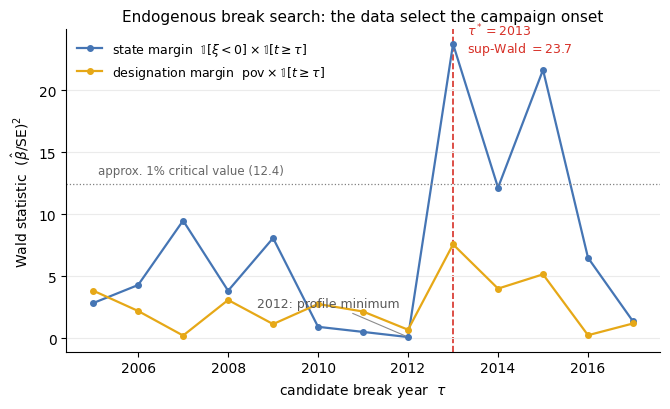

In [8]:
fig, ax = plt.subplots(figsize=(6.8, 4.2))
style = {"state(neg)": (COL["pre"], "state margin  $\\mathbb{1}[\\xi<0]\\times\\mathbb{1}[t\\geq\\tau]$"),
         "designation(pov)": (COL["during"], "designation margin  $\\mathrm{pov}\\times\\mathbb{1}[t\\geq\\tau]$")}
for margin, (c, lab) in style.items():
    m = bs[bs.margin == margin].sort_values("tau")
    ax.plot(m["tau"], m["wald"], "o-", ms=4, lw=1.6, color=c, label=lab)

m = bs[bs.margin == "state(neg)"].sort_values("tau")
star = m.loc[m["wald"].idxmax()]
ax.axvline(2013, color=COL["post"], ls="--", lw=1.2, zorder=0)
ax.annotate(f"$\\tau^*=2013$\nsup-Wald $={star['wald']:.1f}$",
            (2013, star["wald"]), textcoords="offset points", xytext=(10, -6),
            color=COL["post"], fontsize=9)
w12 = float(m.loc[m.tau == 2012, "wald"].iloc[0])
ax.annotate("2012: profile minimum", (2012, w12), textcoords="offset points",
            xytext=(-6, 22), ha="right", fontsize=9, color="0.35",
            arrowprops=dict(arrowstyle="-", lw=0.8, color="0.55"))
ax.axhline(12.4, color="0.5", lw=0.9, ls=":")
ax.text(2005.1, 13.2, "approx. 1% critical value (12.4)", fontsize=8.5, color="0.4")

ax.set_xlabel(r"candidate break year  $\tau$")
ax.set_ylabel(r"Wald statistic  $(\hat\beta/\mathrm{SE})^2$")
ax.set_title("Endogenous break search: the data select the campaign onset", fontsize=11)
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

The state margin's profile has a sharp, unambiguous maximum at 2013 — the campaign onset —
well above the approximate 1% critical value for a searched break. Just as informative,
2012 is the *weakest* point of the entire profile: a break placed one year early explains
essentially nothing, which is what a genuinely abrupt reversal at 2013 looks like. Note
also that the coefficient changes sign across the profile (positive for early candidate
breaks, strongly negative from 2013 on), consistent with the elevated pre-period volatility
seen in the placebo.

## 5. Event-time coefficients

The break search compresses the trajectory into a single number. Replacing the interaction
with a full set of year-specific terms $\mathbb{1}[\xi<0]\times\mathbb{1}[t=y]$ (reference
year 2012) shows the whole path. Coefficients are read from
`results/tables/event_time_coefficients.csv` (`scripts/run_attribution_extras.py`); the figure
reproduced here is SI Figure S5.

In [9]:
ev = pd.read_csv("results/tables/event_time_coefficients.csv").sort_values("year")
print("Event-time coefficients on 1[xi<0] x year (reference 2012):")
for _, r in ev.iterrows():
    tag = "  <- reference" if r["year"] == 2012 else ""
    print(f"  {int(r['year'])}: {r['coef']:+.3f}  (se {r['se']:.3f}){tag}")
pre_m = ev[(ev.year >= 2009) & (ev.year <= 2011)]["coef"].mean()
dur_m = ev[ev.year >= 2013]["coef"].mean()
print(f"\nmean coefficient 2009-2011: {pre_m:+.2f}   mean 2013-2019: {dur_m:+.2f}")

Event-time coefficients on 1[xi<0] x year (reference 2012):
  2000: -0.346  (se 0.256)
  2001: +0.284  (se 0.242)
  2002: -0.355  (se 0.266)
  2003: -0.601  (se 0.240)
  2004: -1.283  (se 0.220)
  2005: -0.528  (se 0.262)
  2006: -0.709  (se 0.225)
  2007: +0.246  (se 0.247)
  2008: -0.593  (se 0.261)
  2009: +1.335  (se 0.292)
  2010: +1.147  (se 0.358)
  2011: -0.483  (se 0.274)
  2012: +0.000  (se 0.000)  <- reference
  2013: -0.897  (se 0.273)
  2014: -0.133  (se 0.285)
  2015: -1.163  (se 0.244)
  2016: -1.239  (se 0.393)
  2017: +0.285  (se 0.342)
  2018: -1.454  (se 0.329)
  2019: -1.446  (se 0.520)

mean coefficient 2009-2011: +0.67   mean 2013-2019: -0.86


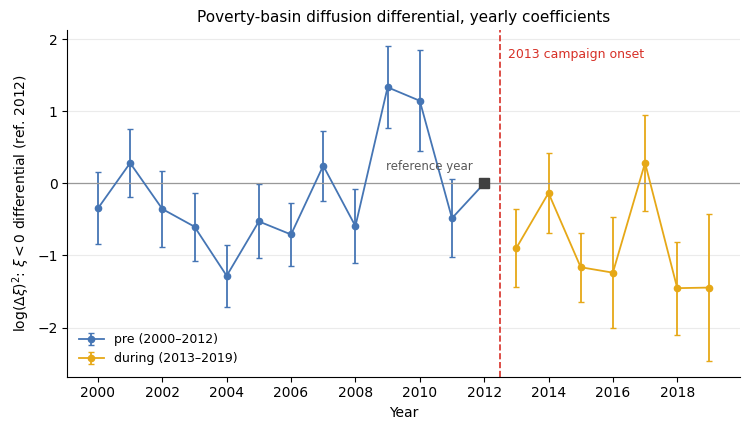

In [10]:
fig, ax = plt.subplots(figsize=(7.6, 4.4))
pre = ev[ev.year <= 2012]
dur = ev[ev.year >= 2013]
for part, per in ((pre, "pre"), (dur, "during")):
    ax.errorbar(part["year"], part["coef"], yerr=1.96 * part["se"], fmt="o-",
                ms=4.5, lw=1.3, capsize=2.5, color=COL[per],
                label=f"{per} ({'2000–2012' if per == 'pre' else '2013–2019'})")
ax.axvline(2012.5, color=COL["post"], ls="--", lw=1.2)
ax.text(2012.75, ax.get_ylim()[1] * 0.82, "2013 campaign onset",
        color=COL["post"], fontsize=9)
ax.plot(2012, 0.0, "s", ms=7, color="0.25", zorder=5)
ax.annotate("reference year", (2012, 0.0), textcoords="offset points",
            xytext=(-8, 10), ha="right", fontsize=8.5, color="0.35")
ax.axhline(0, color="0.6", lw=0.9)
ax.set_xlabel("Year")
ax.set_ylabel(r"$\log(\Delta\xi)^2$: $\xi<0$ differential (ref. 2012)")
ax.set_title("Poverty-basin diffusion differential, yearly coefficients", fontsize=11)
ax.set_xticks(range(2000, 2020, 2))
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.92", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

The trajectory makes the timing concrete. Through the 2000s the differential wanders
without a stable sign, and immediately before the campaign it turns sharply *positive* —
poverty-basin fluctuations were elevated in 2009–2010 (coefficients near $+1.2$) and the
2011–2012 reference region sits close to zero. From 2013 onward almost every year is
negative, averaging about $-0.9$, with the largest compressions in 2015–2016 and 2018–2019.
The pre-campaign elevation is what the pre-period placebo detected; the abrupt reversal at
the campaign onset is what the break search selected.

## 6. How the attribution is stated

The compression of poverty-basin diffusion is **state-targeted and synchronised with the
campaign onset**. Conditional on the state $\xi$, campaign-period fluctuations at $\xi<0$
fall by about 44% ($p < 10^{-4}$), with a further margin aligned with poverty-county
designation ($-34\%$, $p = 0.006$); the designation margin is **placebo-clean** — a
synthetic pre-period break returns a null, and excluding the 2008–2009 crisis leaves it
intact. Letting the break year float freely over 2005–2017 selects 2013 exactly, with 2012
the weakest candidate in the entire profile.

Three qualifications travel with that statement. First, the coarse two-by-two design
detects no designation differential ($\Delta\Delta B = +0.53$, CI $[-1.04, +2.05]$) because
both groups compress; the finer design shows why — designation and state are collinear and
the two margins are not fully separable. Second, the state margin does not have a flat
pre-period baseline, so its identification rests on the timing of the reversal rather than
on a parallel-trends assumption. Third, and decisively: **because the 2013 shift bundled
the broader rural-policy regime — transfers, infrastructure, administrative performance
targets, and rural e-commerce among them — attribution to the poverty campaign
specifically is not identified.** The paper accordingly reports timing and targeting, not
a causal effect of the campaign alone.

### Summary of reproduced quantities

| Quantity | Paper | This notebook |
|---|---|---|
| $B$-ratio cells (pov pre → during) | 1.16 → 0.65 | recomputed |
| $B$-ratio cells (non-pov pre → during) | 1.54 → 0.49 | recomputed |
| Quasi-DiD $\Delta\Delta B$ | +0.53 | recomputed |
| $\Delta\Delta B$ bootstrap CI ($B = 2{,}000$) | [−1.04, +2.05] | read from table |
| S1 designation margin | −0.409, $p = 0.006$ | recomputed |
| S2 state margin | −0.580, $p < 10^{-4}$ | recomputed |
| S2 designation margin (attenuated) | −0.229, $p = 0.14$ | recomputed |
| S2 curvature $\xi^2$ | +0.16, $p < 10^{-4}$ | recomputed |
| Pre-period placebo (designation) | null, $p = 0.29$ | read from table |
| Crisis-excluded designation margin | −0.32, $p = 0.046$ | read from table |
| Endogenous break $\tau^*$ (state margin) | 2013, sup-Wald 23.7 | read from table |
| Event-time path (ref. 2012) | SI Fig. S5 | reproduced from table |